# PPO, DQN and SAC on official control tasks

Maintained Stable-Baselines3 implementations provide practical baselines on LunarLander, CartPole and Pendulum. The repository owns the experiment protocol, selection and audits; it does not claim ownership of the library algorithms. Budgets differ across presets, and every fitting seed remains visible.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/decision_lab").is_dir()
sys.path.insert(0, str(ROOT / "src"))


def read(path):
    return json.loads((ROOT / path).read_text())

## Held-out fitting variability

In [2]:
table = pd.read_csv(ROOT / "docs/comparison.csv")
table[table.task.isin(["LunarLander-v3", "CartPole-v1", "Pendulum-v1"])][
    ["task", "method", "n_fits", "mean_return", "fit_sd", "worst_fit_return", "mean_shift_return"]
]

,task,method,n_fits,mean_return,fit_sd,worst_fit_return,mean_shift_return
2,CartPole-v1,DQN,3,290.773333,181.283988,180.500000,NaN
3,CartPole-v1,PPO,3,500.000000,0.000000,500.000000,NaN
4,LunarLander-v3,DQN,3,262.426932,6.741648,258.056876,153.266969
5,LunarLander-v3,PPO,3,220.533046,11.690516,207.445019,151.431853
6,Pendulum-v1,PPO,3,-184.969763,13.929765,-200.982214,-231.477546
7,Pendulum-v1,SAC,3,-152.199356,0.425188,-152.492493,-166.685876


## Independent episode evidence

test mean 229.93989583250496 fraction >=200 0.82
shift mean 79.50987268665946


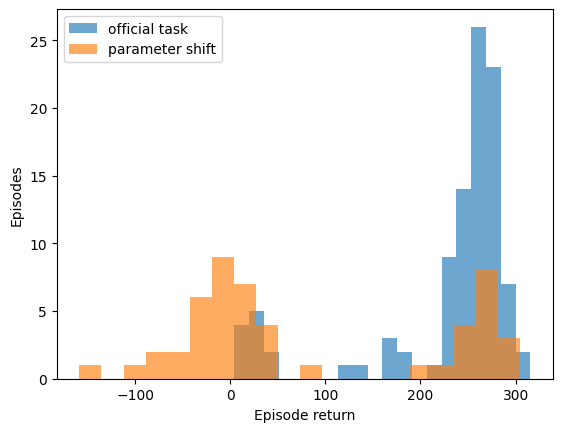

In [3]:
data = np.load(ROOT / "assets/source_data/control/LunarLander-v3_PPO_0.npz")
assert np.array_equal(data["test_seeds"], np.arange(100) + 300000)
print(
    "test mean", data["test_returns"].mean(), "fraction >=200", (data["test_returns"] >= 200).mean()
)
print("shift mean", data["shift_returns"].mean())
plt.hist(data["test_returns"], bins=20, alpha=0.65, label="official task")
plt.hist(data["shift_returns"], bins=20, alpha=0.65, label="parameter shift")
plt.xlabel("Episode return")
plt.ylabel("Episodes")
plt.legend()
plt.show()

## Termination is distinct from success

In [4]:
print("terminated", data["test_terminated"].mean(), "time limit", data["test_truncated"].mean())
assert len(data["test_first_observations"]) == 32
print("Fixed first test reset observations:", data["test_first_observations"][:2])

terminated 0.93 time limit 0.07
Fixed first test reset observations: [[-1.2736320e-03  1.4200418e+00 -1.2902988e-01  4.0541500e-01
   1.4827250e-03  2.9227212e-02  0.0000000e+00  0.0000000e+00]
 [-2.4541854e-03  1.4285783e+00 -1.1712994e-01  3.7939924e-01
   5.7568419e-04 -1.8141503e-02  0.0000000e+00  0.0000000e+00]]


Full fits: `decision-lab control --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.